
=== Final Result ===
True Reward Probabilities: [0.2, 0.5, 0.75]
Estimated Reward Probabilities: [0.28571429 0.47826087 0.        ]
Number of times each arm was selected: [ 7. 92.  1.]
Total Reward Earned: 46


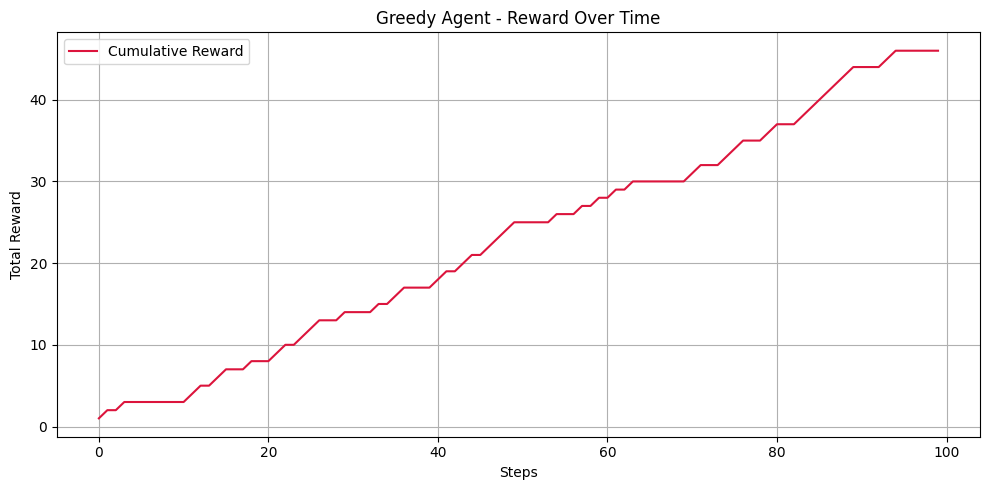

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n_arms = 3
true_rewards = [0.2, 0.5, 0.75]
n_steps = 100

reward_sums = np.zeros(n_arms)
counts = np.zeros(n_arms)
estimated_rewards = np.zeros(n_arms)
reward_history = []
cumulative_reward = []

for arm in range(n_arms):
  reward = int(np.random.rand() < true_rewards[arm])
  reward_sums[arm] += reward
  counts[arm] += 1
  estimated_rewards[arm] = reward_sums[arm] / counts[arm]
  reward_history.append(reward)
  cumulative_reward.append(np.sum(reward_history))

for step in range(n_arms, n_steps):
  arm = np.argmax(estimated_rewards)
  reward = int(np.random.rand() < true_rewards[arm])
  reward_sums[arm] += reward
  counts[arm] += 1
  estimated_rewards[arm] = reward_sums[arm] / counts[arm]
  reward_history.append(reward)
  cumulative_reward.append(cumulative_reward[-1] + reward)

print("\n=== Final Result ===")
print("True Reward Probabilities:", true_rewards)
print("Estimated Reward Probabilities:", estimated_rewards)
print("Number of times each arm was selected:", counts)
print("Total Reward Earned:", int(np.sum(reward_history)))

plt.figure(figsize=(10, 5))
plt.plot(cumulative_reward, label="Cumulative Reward", color='crimson')
plt.xlabel("Steps")
plt.ylabel("Total Reward")
plt.title("Greedy Agent - Reward Over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()